In [14]:
import glob
import os
import pathlib
import re
from collections import Counter

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers, models, callbacks

SEED = 123
IMG_SIZE = (64, 64)
BATCH_SIZE = 64
EPOCHS = 40
tf.keras.utils.set_random_seed(SEED)

print("GPUs available:", len(tf.config.list_physical_devices("GPU")))

GPUs available: 2


In [15]:
# FINDINGS: the dataset is FLAT: 27,000 .jpg files in a single "Dataset/" folder with no class
# sub-folders. image_dataset_from_directory therefore saw ONE class -> Dense(1, softmax) -> always 1.0,
# loss 0, accuracy 0. The class is encoded in the filename instead (e.g. "Forest_123.jpg"),
# so we read labels from the names and build the tf.data pipeline ourselves.
path = kagglehub.dataset_download("raoofnaushad/eurosat-sentinel2-dataset")
files = sorted(glob.glob(os.path.join(path, "**", "*.jpg"), recursive=True))
print(f"{len(files)} images; examples:", [os.path.basename(f) for f in files[:3]])


def label_of(filepath):
    """'AnnualCrop_123.jpg' -> 'AnnualCrop' (strips the trailing index)."""
    return re.sub(r"[_\-\s]*\d+$", "", pathlib.Path(filepath).stem)


labels_str = [label_of(f) for f in files]
class_names = sorted(set(labels_str))
num_classes = len(class_names)
print("Class counts:", dict(Counter(labels_str)))
assert 2 <= num_classes <= 50, (
    f"Label parsing gave {num_classes} classes; check the filename pattern: "
    f"{[os.path.basename(f) for f in files[:10]]}")

class_to_idx = {c: i for i, c in enumerate(class_names)}
labels = np.array([class_to_idx[c] for c in labels_str], dtype="int32")
files = np.array(files)

27000 images; examples: ['AnnualCrop_1.jpg', 'AnnualCrop_10.jpg', 'AnnualCrop_100.jpg']
Class counts: {'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}


In [16]:
train_f, temp_f, train_y, temp_y = train_test_split(
    files, labels, test_size=0.30, stratify=labels, random_state=SEED)
val_f, test_f, val_y, test_y = train_test_split(
    temp_f, temp_y, test_size=0.50, stratify=temp_y, random_state=SEED)
print(f"train {len(train_f)} | val {len(val_f)} | test {len(test_f)}")

AUTOTUNE = tf.data.AUTOTUNE


def load_image(filepath, label):
    img = tf.io.read_file(filepath)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)          # float32 in [0, 255]
    return img, label


def make_ds(f, y, training=False):
    ds = tf.data.Dataset.from_tensor_slices((f, y)).map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()                               # cache decoded images; augmentation lives in the model
    if training:
        ds = ds.shuffle(len(f), seed=SEED)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_ds = make_ds(train_f, train_y, training=True)
val_ds = make_ds(val_f, val_y)
test_ds = make_ds(test_f, test_y)               # not shuffled, so predictions line up with labels

train 18900 | val 4050 | test 4050


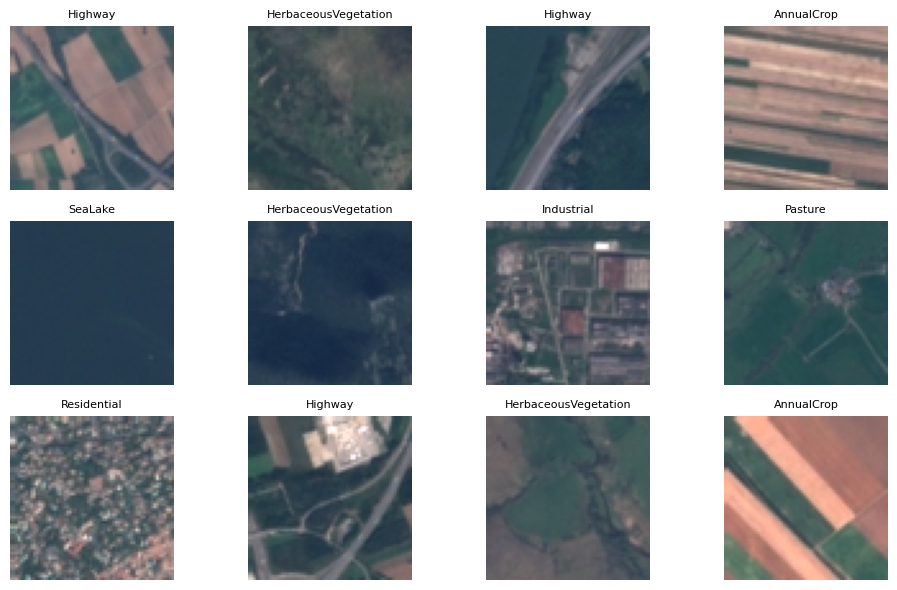

In [17]:
plt.figure(figsize=(10, 6))
for images, labels in train_ds.take(1):
    for i in range(12):
        plt.subplot(3, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]], fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [18]:
# Satellite tiles have no canonical orientation, so flips/rotations are safe augmentations.
augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
], name="augmentation")


def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    return layers.MaxPooling2D()(x)


inputs = layers.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = layers.Rescaling(1.0 / 255)(x)
for f in (32, 64, 128):
    x = conv_block(x, f)
x = layers.GlobalAveragePooling2D()(x)   # far fewer params than Flatten + Dense(128)
x = layers.Dropout(0.4)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes)(x)   # raw logits; loss uses from_logits=True

model = models.Model(inputs, outputs, name="eurosat_cnn")

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
model.summary()

Model: "eurosat_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 32)     │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_6 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_7 (Activation)       │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 32, 32, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 16, 16, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 16, 16, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 306,154 (1.17 MB)

 Trainable params: 305,258 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

In [ ]:
# cbs = [
#     callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
#     callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
#     callbacks.ModelCheckpoint("eurosat_best.keras", monitor="val_accuracy", save_best_only=True),
# ]
# history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=cbs)
cbs = [
    callbacks.EarlyStopping(monitor="val_accuracy", patience=8, restore_best_weights=True),
    callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5),
    callbacks.ModelCheckpoint("eurosat_best.keras", monitor="val_accuracy", save_best_only=True),
]

history = model.fit(
    train_ds, 
    validation_data=val_ds, 
    epochs=EPOCHS, 
    callbacks=cbs
)

Epoch 1/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.6048 - loss: 1.1411 - val_accuracy: 0.2096 - val_loss: 3.3914 - learning_rate: 0.0010
Epoch 2/40
296/296 ━━━━━━━━━━━━━━━━━━━━ 16s 55ms/step - accuracy: 0.7186 - loss: 0.8300 - val_accuracy: 0.5365 - val_loss: 1.5393 - learning_rate: 0.0010
Epoch 3/40
 26/296 ━━━━━━━━━━━━━━━━━━━━ 14s 52ms/step - accuracy: 0.7543 - loss: 0.7053

In [ ]:
h = history.history
epochs_range = range(1, len(h["accuracy"]) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, h["accuracy"], label="Train")
plt.plot(epochs_range, h["val_accuracy"], label="Validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend(loc="lower right")
plt.subplot(1, 2, 2)
plt.plot(epochs_range, h["loss"], label="Train")
plt.plot(epochs_range, h["val_loss"], label="Validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend(loc="upper right")
plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc * 100:.2f}%")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(num_classes), class_names, rotation=45, ha="right")
plt.yticks(range(num_classes), class_names)
for i in range(num_classes):
    for j in range(num_classes):
        plt.text(j, i, cm[i, j], ha="center", va="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
plt.title("Confusion matrix (test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()

In [ ]:
images, labels = next(iter(test_ds))
probs = tf.nn.softmax(model.predict(images[:1], verbose=0)[0]).numpy()
pred = int(np.argmax(probs))
plt.figure(figsize=(4, 4))
plt.imshow(images[0].numpy().astype("uint8"))
plt.title(f"True: {class_names[labels[0]]}\nPred: {class_names[pred]} ({probs[pred] * 100:.1f}%)")
plt.axis("off")
plt.show()

In [ ]:
model.save("eurosat_cnn_model.keras")
loaded = tf.keras.models.load_model("eurosat_cnn_model.keras")
print("Saved and reloaded OK. Classes:", class_names)